# 7 · One-call API — quickplot / quickmap

`digitalearth.quickplot` (alias `quickmap`) builds a **finished, decorated `Map` in a single call**: it dispatches on the input type (raster → field, point features → points, polygons → choropleth), auto-styles by variable, draws, and adds a colorbar — returning the `Map` so you can keep tweaking it.

Module-level functions (`api.field`, `api.contours`, …) mirror the `Map` methods for a terse functional style. This is the highest-level entry point; everything in notebooks 2–6 is what it orchestrates under the hood.

**Setup.** Inline plots + resolve the DEM path.

In [1]:
%matplotlib inline
from pathlib import Path

# Resolve the repo root so the bundled sample DEM is found whether this runs from
# docs/examples/ (mkdocs) or the repository root.
ROOT = Path.cwd()
while not (ROOT / "examples" / "data" / "LisbonElevation.tif").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DEM = str(ROOT / "examples" / "data" / "LisbonElevation.tif")
print("DEM:", DEM)

DEM: /home/runner/work/Digital-Earth/Digital-Earth/examples/data/LisbonElevation.tif


Import the one-call API (`digitalearth.quickplot`/`quickmap`) and the module-function namespace (`digitalearth.api`), and read the DEM.

In [2]:
import digitalearth
from digitalearth import api
from pyramids.dataset import Dataset

ds = Dataset.read_file(DEM)

## A raster in one call (with a colorbar)

**quickplot(dataset)** — one call builds a `Map`, auto-styles, draws the raster and adds a colorbar, returning the finished `Map` (so `set_title` still works afterwards).

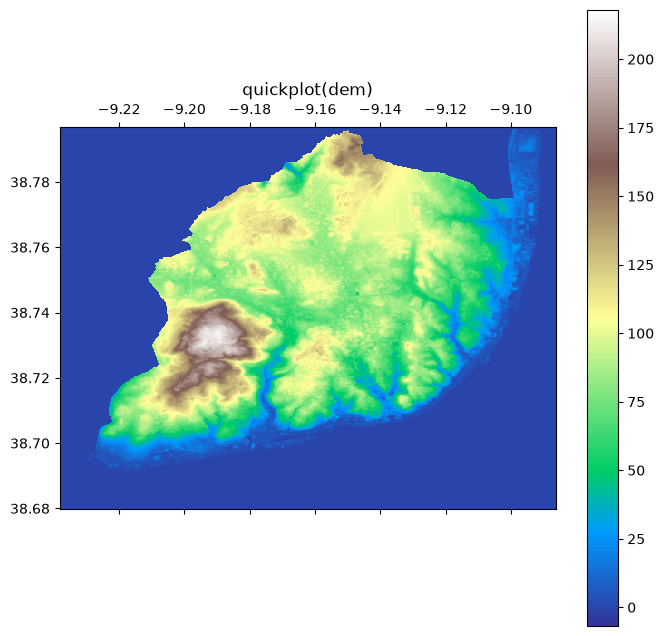

In [3]:
m = digitalearth.quickplot(ds, crs=ds.epsg, cmap='terrain')
m.set_title('quickplot(dem)')
m.fig;

## Choose the renderer

Pick the renderer with a module function — `api.contours(filled=True)` is the functional twin of `Map.contours(filled=True)`; the same `levels`/`cmap` kwargs apply.

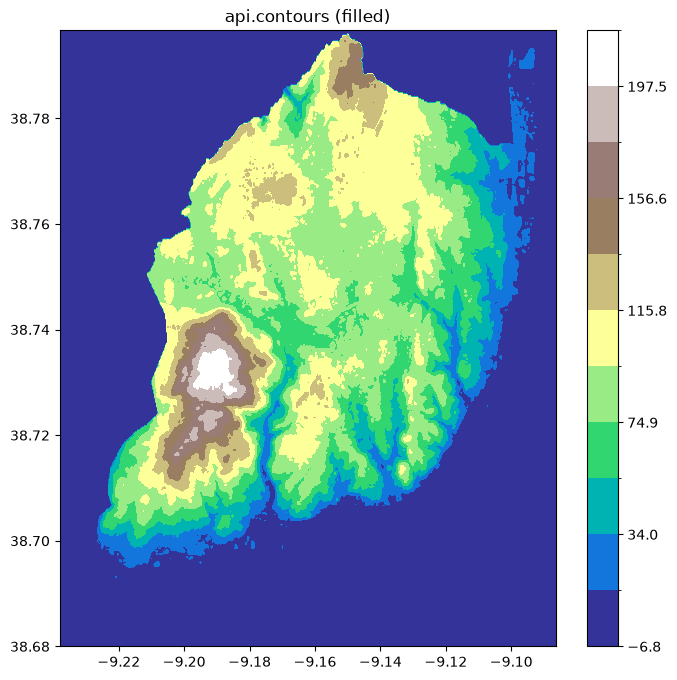

In [4]:
m = api.contours(ds, crs=ds.epsg, levels=12, cmap='terrain', filled=True)
m.set_title('api.contours (filled)')
m.fig;

## Reproject + colorbar in one call

Reproject in the same one call — `api.field(..., crs=3857)` builds the map directly in Web Mercator.

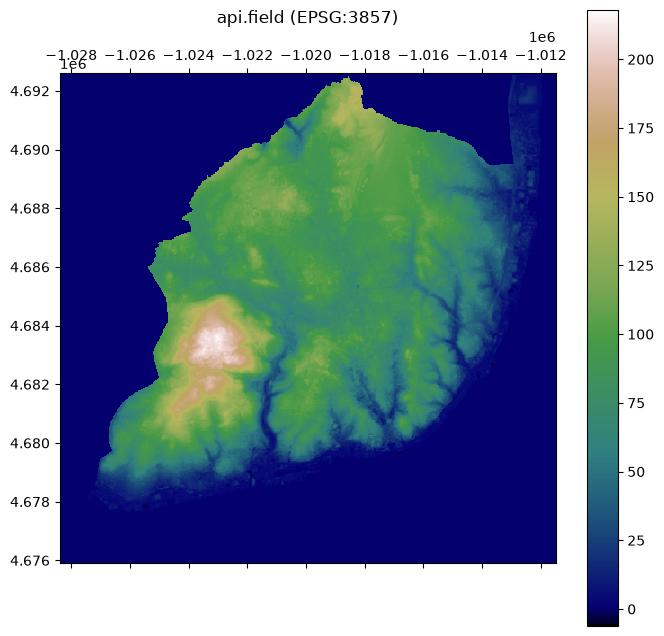

In [5]:
m = api.field(ds, crs=3857, cmap='gist_earth')
m.set_title('api.field (EPSG:3857)')
m.fig;